# <FONT SIZE=5 COLOR="purple"> Punto 2. Modelos de CNN — Clasificador de Pokémon </FONT>

## <FONT SIZE=4 COLOR="green"> Planteamiento del problema </FONT>

Se construyó un dataset propio mediante *web scraping* (script `test.py`): para cada uno de los **386 Pokémon** de las
generaciones I a III (#0001 Bulbasaur – #0386 Deoxys) se descargaron hasta 50 imágenes de Google Imágenes
(≈19.000 imágenes en total). Cada carpeta `dataset/NNNN_Nombre/` corresponde a una clase.

**Problema:** clasificación multiclase (386 clases): dada una imagen, predecir qué Pokémon aparece y con qué probabilidad.

**Retos del dataset**
- Muchas clases y pocas imágenes por clase (≈31–50) → entrenar una CNN desde cero es difícil.
- Imágenes muy heterogéneas: arte oficial, sprites, cartas, peluches, *fan-art*, capturas del anime, fondos variados.
- Ruido de etiqueta (Google puede devolver imágenes de otro Pokémon o con varios Pokémon).

**Estrategia**
1. Limpieza del dataset (imágenes corruptas, transparencias, duplicados).
2. División estratificada *train / validation / test* (70 / 15 / 15).
3. **Modelo base:** CNN construida desde cero con *Data Augmentation* (referencia).
4. **Transfer Learning** con **EfficientNetV2-B0** preentrenada en ImageNet (extractor de características congelado).
5. **Fine-tuning** de las últimas capas de EfficientNet con una tasa de aprendizaje baja.
6. Evaluación en *test*: accuracy, top-5 accuracy, precision, recall y F1 (macro), clases más confundidas y predicciones.
7. Exportar el modelo para la interfaz **Gradio** (Módulo 2).

> Se recomienda ejecutar en **Google Colab con GPU** (`Entorno de ejecución → Cambiar tipo de entorno → T4 GPU`).

## <FONT SIZE=4 COLOR="green"> 1. Librerías y configuración </FONT>

In [8]:
import os, sys, json, random, hashlib, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support)
import kagglehub
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("GPU:", GPUS if GPUS else "no hay GPU (el entrenamiento será lento)")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COLOR_TRAIN, COLOR_VAL = "#1f77b4", "#ff7f0e"

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
# ---------------- Rutas ----------------
import kagglehub

EN_COLAB = "google.colab" in sys.modules
WORK_DIR = Path("/content") if EN_COLAB else Path(".")

# Descarga directa desde Kaggle (queda en caché: la 2ª vez no vuelve a bajar)
KAGGLE_DIR = Path(kagglehub.dataset_download("sparta551/pokemon-daraset"))
print("Descargado en:", KAGGLE_DIR)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

def encontrar_carpeta_clases(raiz: Path) -> Path:
  """Devuelve la carpeta con más subcarpetas-clase que contengan imágenes."""
  mejor, mejor_n = None, 0
  for d in [raiz, *[p for p in raiz.rglob("*") if p.is_dir()]]:
    n = sum(
      1 for sub in d.iterdir()
      if sub.is_dir() and any(f.suffix.lower() in IMG_EXTS for f in sub.iterdir() if f.is_file())
    )
    if n > mejor_n:
      mejor, mejor_n = d, n
  assert mejor is not None, f"No se encontraron carpetas de clases dentro de {raiz}"
  return mejor

DATA_DIR = encontrar_carpeta_clases(KAGGLE_DIR)
print("DATA_DIR:", DATA_DIR, "| clases:", sum(1 for p in DATA_DIR.iterdir() if p.is_dir()))

CLEAN_DIR    = WORK_DIR / "dataset_limpio"            # copia limpia y redimensionada
MODEL_PATH   = WORK_DIR / "modelo_cnn_pokemon.keras"  # modelo final para Gradio
CLASSES_PATH = WORK_DIR / "clases_pokemon.json"

# ---------------- Hiperparámetros ----------------
IMG_SIZE    = 224
BATCH_SIZE  = 64
EPOCHS_BASE = 30     # CNN desde cero
EPOCHS_TL   = 15     # transfer learning (base congelada)
EPOCHS_FT   = 15     # fine-tuning
FT_LAYERS   = 60     # nº de capas finales de EfficientNet que se descongelan

if GPUS:   # precisión mixta: ~2x más rápido en GPU T4
  keras.mixed_precision.set_global_policy("mixed_float16")

assert DATA_DIR.exists(), f"No se encuentra la carpeta {DATA_DIR}"

Using Colab cache for faster access to the 'pokemon-daraset' dataset.
Descargado en: /kaggle/input/pokemon-daraset
DATA_DIR: /kaggle/input/pokemon-daraset/dataset | clases: 386


## <FONT SIZE=4 COLOR="green"> 2. Exploración del dataset </FONT>

In [12]:
EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif"}
carpetas = sorted([d for d in DATA_DIR.iterdir() if d.is_dir()])
registros = [(d.name, str(f)) for d in carpetas for f in sorted(d.iterdir()) if f.suffix.lower() in EXT]
df_raw = pd.DataFrame(registros, columns=["carpeta", "ruta"])

def nombre_bonito(carpeta):
    num, nombre = carpeta.split("_", 1)
    return f"{nombre} (#{num})"

conteo = df_raw["carpeta"].value_counts().sort_index()
print(f"Clases: {len(carpetas)}  |  Imágenes: {len(df_raw)}")
print(conteo.describe().round(1).to_string())

Clases: 386  |  Imágenes: 19064
count    386.0
mean      49.4
std        2.3
min       31.0
25%       50.0
50%       50.0
75%       50.0
max       50.0


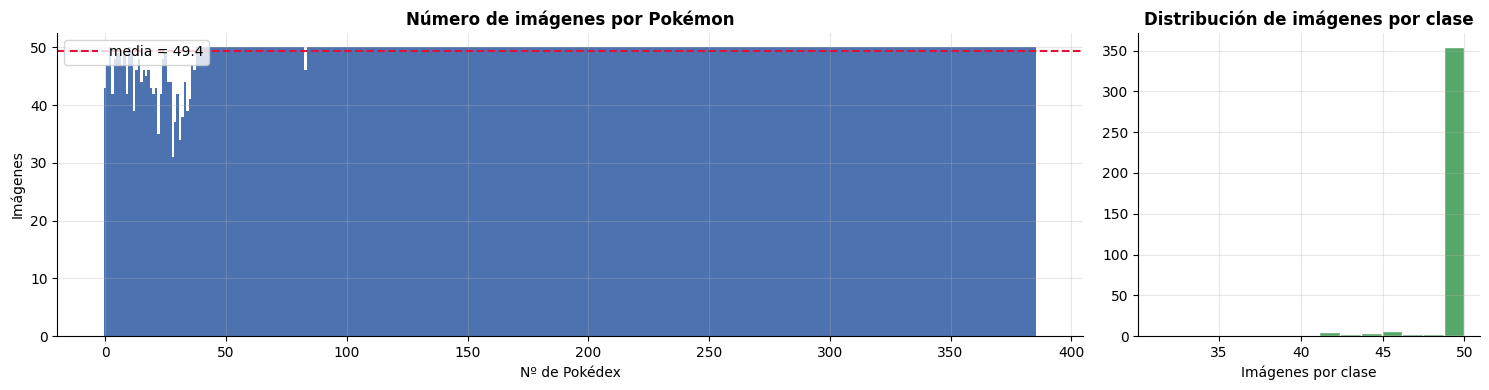

Clases con menos imágenes:
carpeta
Nidoran F (#0029)    31
Nidoran M (#0032)    34
Ekans (#0023)        35
Nidorina (#0030)     37
Nidorino (#0033)     38
Clefairy (#0035)     39
Weedle (#0013)       39
Clefable (#0036)     41


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
axes[0].bar(range(len(conteo)), conteo.values, color="#4C72B0", width=1.0)
axes[0].set_title("Número de imágenes por Pokémon")
axes[0].set_xlabel("Nº de Pokédex"); axes[0].set_ylabel("Imágenes")
axes[0].axhline(conteo.mean(), color="crimson", ls="--", label=f"media = {conteo.mean():.1f}")
axes[0].legend()
axes[1].hist(conteo.values, bins=15, color="#55A868", edgecolor="white")
axes[1].set_title("Distribución de imágenes por clase"); axes[1].set_xlabel("Imágenes por clase")
plt.tight_layout(); plt.show()

print("Clases con menos imágenes:")
print(conteo.sort_values().head(8).rename(index=nombre_bonito).to_string())

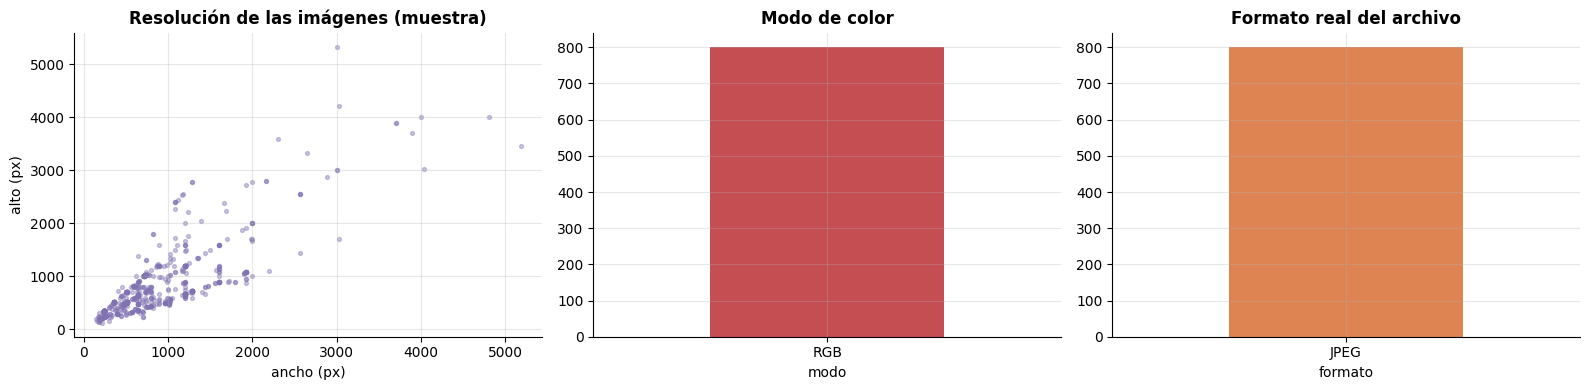

In [14]:
# Tamaños y formatos de una muestra de imágenes
muestra = df_raw.sample(min(800, len(df_raw)), random_state=SEED)
info = []
for r in muestra["ruta"]:
    try:
        with Image.open(r) as im:
            info.append((im.width, im.height, im.mode, im.format))
    except Exception:
        info.append((np.nan, np.nan, "error", "error"))
df_info = pd.DataFrame(info, columns=["ancho", "alto", "modo", "formato"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(df_info["ancho"], df_info["alto"], s=8, alpha=0.4, color="#8172B2")
axes[0].set_title("Resolución de las imágenes (muestra)"); axes[0].set_xlabel("ancho (px)"); axes[0].set_ylabel("alto (px)")
df_info["modo"].value_counts().plot.bar(ax=axes[1], color="#C44E52"); axes[1].set_title("Modo de color")
df_info["formato"].value_counts().plot.bar(ax=axes[2], color="#DD8452"); axes[2].set_title("Formato real del archivo")
for ax in axes[1:]: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

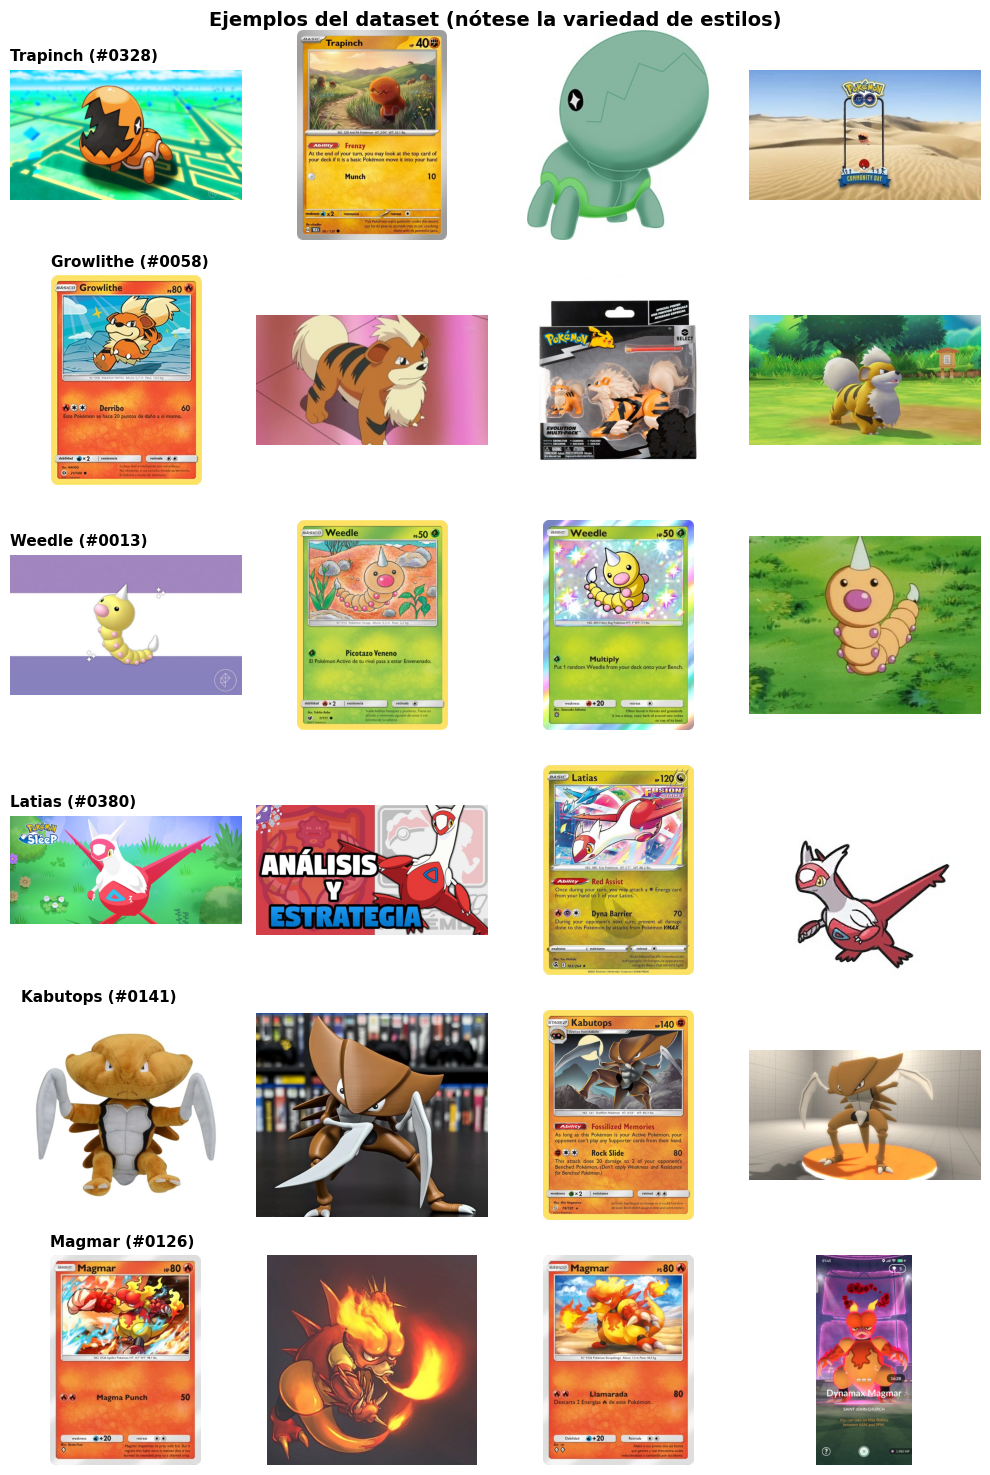

In [15]:
# Ejemplos: 4 imágenes de 6 Pokémon elegidos al azar
ej = random.Random(SEED).sample(list(conteo.index), 6)
fig, axes = plt.subplots(6, 4, figsize=(10, 15))
for i, c in enumerate(ej):
    rutas = df_raw[df_raw.carpeta == c]["ruta"].sample(4, random_state=SEED).tolist()
    for j, r in enumerate(rutas):
        ax = axes[i, j]
        ax.imshow(ImageOps.exif_transpose(Image.open(r)).convert("RGB")); ax.axis("off")
        if j == 0: ax.set_title(nombre_bonito(c), loc="left", fontsize=11)
plt.suptitle("Ejemplos del dataset (nótese la variedad de estilos)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

## <FONT SIZE=4 COLOR="green"> 3. Limpieza del dataset </FONT>

Como las imágenes vienen de Google, se aplican los siguientes pasos y se guarda una copia limpia en `dataset_limpio/`:
- Se descartan archivos corruptos o que no se pueden abrir, y las imágenes muy pequeñas (< 48 px).
- Se corrige la orientación EXIF y las imágenes con transparencia (PNG/WebP/GIF) se componen sobre fondo blanco.
- Todo se convierte a **RGB JPEG** y se reduce a un lado máximo de 320 px (acelera mucho la lectura).
- Se eliminan **duplicados dentro de cada clase** usando un *hash perceptual* (evita que la misma imagen quede en *train* y en *test*).

In [16]:
MAX_LADO, MIN_LADO = 320, 48

def hash_perceptual(im, n=8):
    g = np.asarray(im.convert("L").resize((n, n), Image.BILINEAR), dtype=np.float32)
    return hashlib.md5((g > g.mean()).tobytes()).hexdigest()

def limpiar(args):
    carpeta, ruta, destino = args
    try:
        with Image.open(ruta) as im:
            im = ImageOps.exif_transpose(im)
            if im.mode in ("RGBA", "LA", "P"):
                im = im.convert("RGBA")
                fondo = Image.new("RGBA", im.size, (255, 255, 255, 255))
                im = Image.alpha_composite(fondo, im)
            im = im.convert("RGB")
            if min(im.size) < MIN_LADO:
                return carpeta, None, None, "muy pequeña"
            im.thumbnail((MAX_LADO, MAX_LADO))
            h = hash_perceptual(im)
            destino.parent.mkdir(parents=True, exist_ok=True)
            im.save(destino, "JPEG", quality=92)
            return carpeta, str(destino), h, "ok"
    except Exception:
        return carpeta, None, None, "corrupta"

if CLEAN_DIR.exists():
    shutil.rmtree(CLEAN_DIR)
tareas = [(c, r, CLEAN_DIR / c / (Path(r).stem + ".jpg")) for c, r in df_raw.itertuples(index=False)]
with ThreadPoolExecutor(max_workers=8) as ex:
    res = list(ex.map(limpiar, tareas, chunksize=64))
df_l = pd.DataFrame(res, columns=["carpeta", "ruta", "hash", "estado"])

dup = df_l["estado"].eq("ok") & df_l.duplicated(["carpeta", "hash"])
for r in df_l.loc[dup, "ruta"]:
    os.remove(r)
df_l.loc[dup, "estado"] = "duplicada"

resumen = df_l["estado"].value_counts()
print(resumen.to_string())
df = df_l[df_l.estado == "ok"][["carpeta", "ruta"]].reset_index(drop=True)
print(f"\nImágenes finales: {len(df)}  ({len(df)/len(df_raw):.1%} del total original)")

estado
ok           18764
duplicada      300

Imágenes finales: 18764  (98.4% del total original)


## <FONT SIZE=4 COLOR="green"> 4. División train / validation / test (estratificada) </FONT>

In [17]:
CLASES = sorted(df["carpeta"].unique())
NUM_CLASES = len(CLASES)
clase_a_idx = {c: i for i, c in enumerate(CLASES)}
df["y"] = df["carpeta"].map(clase_a_idx)

df_train, df_tmp = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
df_val, df_test  = train_test_split(df_tmp, test_size=0.50, stratify=df_tmp["y"], random_state=SEED)

tabla_split = pd.DataFrame({
    "imágenes": [len(df_train), len(df_val), len(df_test)],
    "% del total": [f"{len(x)/len(df):.0%}" for x in (df_train, df_val, df_test)],
    "img. por clase (media)": [round(len(x)/NUM_CLASES, 1) for x in (df_train, df_val, df_test)],
}, index=["train", "validation", "test"])
print("Número de clases:", NUM_CLASES)
tabla_split

Número de clases: 386


,imágenes,% del total,img. por clase (media)
train,13134,70%,34.0
validation,2815,15%,7.3
test,2815,15%,7.3


In [18]:
AUTOTUNE = tf.data.AUTOTUNE

def cargar(ruta, y):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)   # valores 0–255
    return tf.cast(img, tf.uint8), tf.one_hot(y, NUM_CLASES)

def crear_ds(d, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((d["ruta"].values, d["y"].values))
    ds = ds.map(cargar, num_parallel_calls=AUTOTUNE).cache()
    if entrenamiento:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train_ds = crear_ds(df_train, entrenamiento=True)
val_ds   = crear_ds(df_val)
test_ds  = crear_ds(df_test)
print(train_ds.element_spec)

(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 386), dtype=tf.float32, name=None))


## <FONT SIZE=4 COLOR="green"> 5. Data Augmentation </FONT>
Las transformaciones se aplican solo durante el entrenamiento (las capas se desactivan en inferencia).

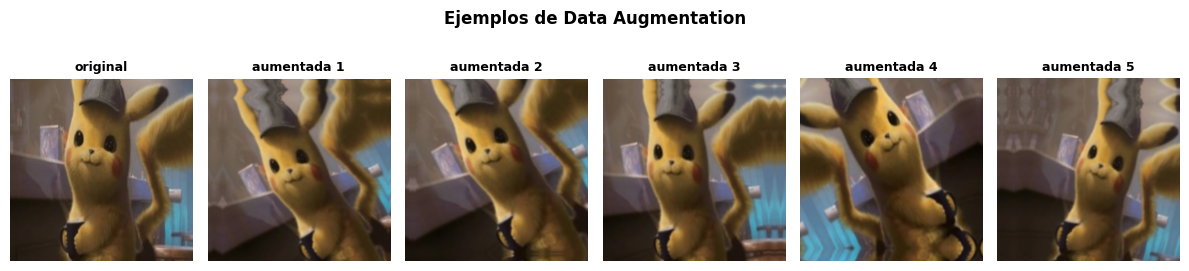

In [19]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom((-0.15, 0.15)),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="data_augmentation")

x_ej, _ = next(iter(train_ds.take(1)))
img = x_ej[:1]
plt.figure(figsize=(12, 3))
for i in range(6):
    ax = plt.subplot(1, 6, i + 1)
    aug = img if i == 0 else data_augmentation(img, training=True)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8")); plt.axis("off")
    plt.title("original" if i == 0 else f"aumentada {i}", fontsize=9)
plt.suptitle("Ejemplos de Data Augmentation", fontweight="bold"); plt.tight_layout(); plt.show()

## <FONT SIZE=4 COLOR="green"> 6. Utilidades de entrenamiento y gráficas </FONT>
Se usa `label smoothing` (0.1) porque las etiquetas obtenidas por scraping tienen algo de ruido,
y además de *accuracy* se reporta **top-5 accuracy** (la clase correcta está entre las 5 más probables).

In [20]:
def compilar(modelo, lr):
    modelo.compile(optimizer=keras.optimizers.Adam(lr),
                   loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
                   metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=5, name="top5")])

def callbacks(nombre, paciencia=5):
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=paciencia,
                                          restore_best_weights=True, verbose=1),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2,
                                              min_lr=1e-7, verbose=1),
            keras.callbacks.ModelCheckpoint(str(WORK_DIR / f"{nombre}.keras"), monitor="val_accuracy",
                                            save_best_only=True)]

def graficar_historia(historias, titulo, corte=None):
    h = {}
    for hist in historias:
        for k, v in hist.history.items():
            h.setdefault(k, []).extend(v)
    ep = np.arange(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, m, nom in zip(axes, ["loss", "accuracy", "top5"], ["Loss", "Accuracy", "Top-5 accuracy"]):
        ax.plot(ep, h[m], "o-", ms=3, color=COLOR_TRAIN, label="entrenamiento")
        ax.plot(ep, h["val_" + m], "s-", ms=3, color=COLOR_VAL, label="validación")
        if corte:
            ax.axvline(corte + 0.5, color="gray", ls="--")
            ax.text(corte + 0.7, ax.get_ylim()[1], " inicio fine-tuning", va="top", color="gray", fontsize=9)
        ax.set_title(nom); ax.set_xlabel("Época"); ax.legend()
    plt.suptitle(titulo, fontsize=14, fontweight="bold"); plt.tight_layout(); plt.show()

## <FONT SIZE=4 COLOR="green"> 7. Modelo 1: CNN desde cero (modelo base) </FONT>
Arquitectura clásica de 4 bloques convolucionales (Conv → BatchNorm → ReLU → MaxPooling),
seguida de *Global Average Pooling*, *Dropout* y una capa densa *softmax* con 386 salidas.

In [21]:
def bloque(x, filtros):
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)

entrada = keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(entrada)
x = layers.Rescaling(1 / 255.0)(x)
for f in (32, 64, 128, 256):
    x = bloque(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
salida = layers.Dense(NUM_CLASES, activation="softmax", dtype="float32")(x)
modelo_base = keras.Model(entrada, salida, name="CNN_desde_cero")

compilar(modelo_base, 1e-3)
modelo_base.summary()

Model: "CNN_desde_cero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,274,338 (4.86 MB)

 Trainable params: 1,272,418 (4.85 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 110s 460ms/step - accuracy: 0.0041 - loss: 5.9906 - top5: 0.0212 - val_accuracy: 0.0039 - val_loss: 5.9996 - val_top5: 0.0135 - learning_rate: 0.0010
Epoch 2/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 89s 432ms/step - accuracy: 0.0061 - loss: 5.7699 - top5: 0.0394 - val_accuracy: 0.0092 - val_loss: 5.8904 - val_top5: 0.0362 - learning_rate: 0.0010
Epoch 3/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 88s 425ms/step - accuracy: 0.0155 - loss: 5.6188 - top5: 0.0660 - val_accuracy: 0.0078 - val_loss: 6.3231 - val_top5: 0.0387 - learning_rate: 0.0010
Epoch 4/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.0172 - loss: 5.5193 - top5: 0.0819
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
206/206 ━━━━━━━━━━━━━━━━━━━━ 88s 427ms/step - accuracy: 0.0191 - loss: 5.5030 - top5: 0.0837 - val_accuracy: 0.0135 - val_loss: 5.9551 - val_top5: 0.0686 - learning_rate: 0.0010
Epoch 5/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 88s 427ms/step - accuracy: 0.0292 -

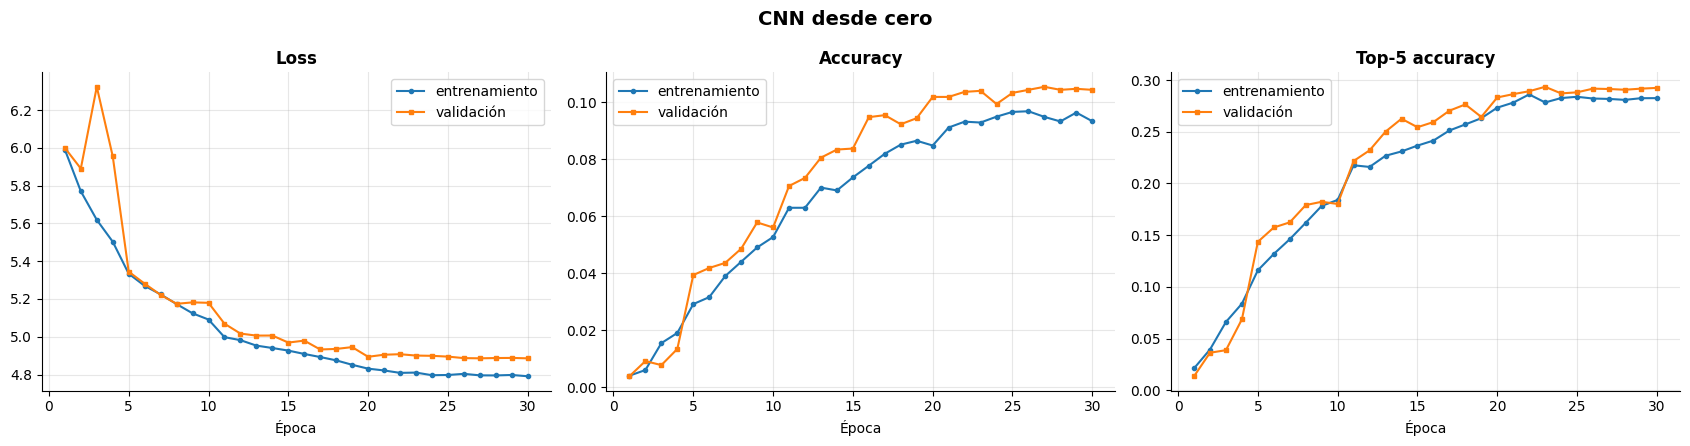

In [22]:
hist_base = modelo_base.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASE,
                            callbacks=callbacks("cnn_desde_cero", paciencia=6))
graficar_historia([hist_base], "CNN desde cero")

## <FONT SIZE=4 COLOR="green"> 8. Modelo 2: Transfer Learning con EfficientNetV2-B0 </FONT>

**Fase 1 — extractor de características:** se usa EfficientNetV2-B0 preentrenada en ImageNet (≈ 1,3 millones de imágenes)
**con sus pesos congelados**, y solo se entrena una nueva cabeza de clasificación.
EfficientNetV2 incluye internamente su preprocesamiento, por lo que recibe la imagen en el rango 0–255.

In [23]:
base = keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet",
                                           input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

entrada = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="imagen")
x = data_augmentation(entrada)
x = base(x, training=False)          # BatchNorm de la base siempre en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(NUM_CLASES, activation="softmax", dtype="float32", name="pokemon")(x)
modelo_tl = keras.Model(entrada, salida, name="EfficientNetV2B0_pokemon")

compilar(modelo_tl, 1e-3)
modelo_tl.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetV2B0_pokemon"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pokemon (Dense)                 │ (None, 386)            │       494,466 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,418,898 (24.49 MB)

 Trainable params: 497,026 (1.90 MB)

 Non-trainable params: 5,921,872 (22.59 MB)

Epoch 1/15
206/206 ━━━━━━━━━━━━━━━━━━━━ 48s 158ms/step - accuracy: 0.0736 - loss: 5.6269 - top5: 0.1675 - val_accuracy: 0.2519 - val_loss: 4.5686 - val_top5: 0.4394 - learning_rate: 0.0010
Epoch 2/15
206/206 ━━━━━━━━━━━━━━━━━━━━ 28s 135ms/step - accuracy: 0.2906 - loss: 4.0616 - top5: 0.4911 - val_accuracy: 0.3506 - val_loss: 3.8883 - val_top5: 0.5428 - learning_rate: 0.0010
Epoch 3/15
206/206 ━━━━━━━━━━━━━━━━━━━━ 28s 138ms/step - accuracy: 0.4003 - loss: 3.4951 - top5: 0.6197 - val_accuracy: 0.3776 - val_loss: 3.7459 - val_top5: 0.5776 - learning_rate: 0.0010
Epoch 4/15
206/206 ━━━━━━━━━━━━━━━━━━━━ 28s 135ms/step - accuracy: 0.4604 - loss: 3.2072 - top5: 0.6856 - val_accuracy: 0.3897 - val_loss: 3.7154 - val_top5: 0.5975 - learning_rate: 0.0010
Epoch 5/15
206/206 ━━━━━━━━━━━━━━━━━━━━ 28s 135ms/step - accuracy: 0.5027 - loss: 3.0147 - top5: 0.7256 - val_accuracy: 0.3957 - val_loss: 3.6778 - val_top5: 0.6067 - learning_rate: 0.0010
Epoch 6/15
206/206 ━━━━━━━━━━━━━━━━━━━━ 28s 137ms/step 

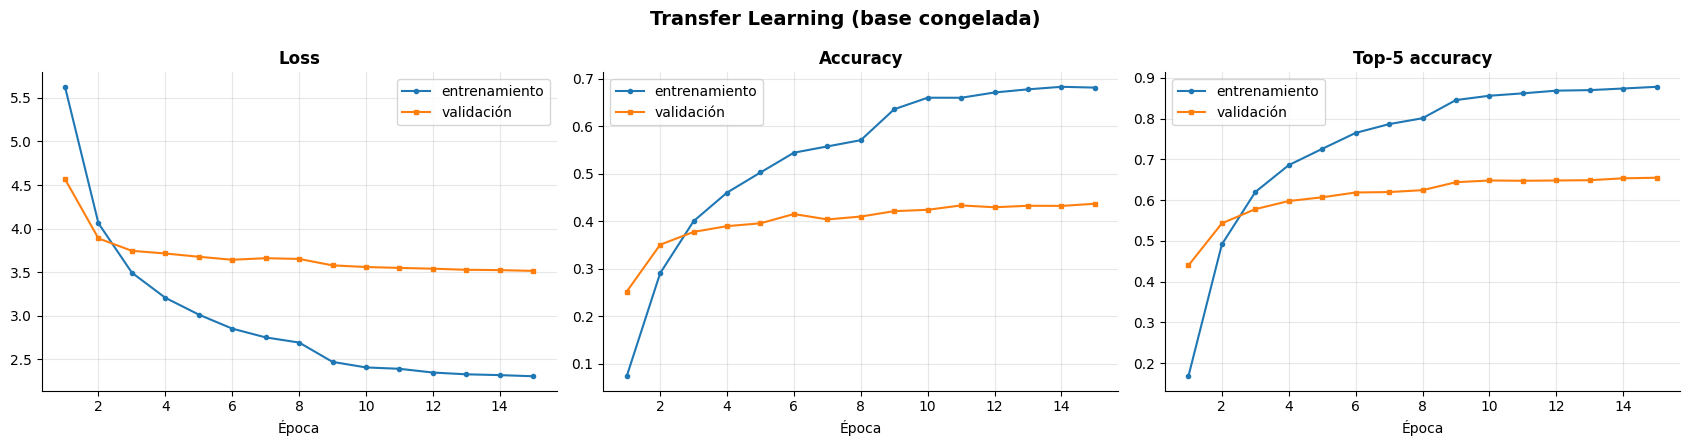

In [24]:
hist_tl = modelo_tl.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TL,
                        callbacks=callbacks("tl_congelado", paciencia=4))
graficar_historia([hist_tl], "Transfer Learning (base congelada)")

### Fase 2 — Fine-tuning
Se descongelan las últimas capas de EfficientNet (las de características más específicas) y se reentrena
con una tasa de aprendizaje 10 veces menor, para ajustar ligeramente los filtros al dominio de los Pokémon
sin destruir lo aprendido en ImageNet. Las capas *BatchNormalization* se mantienen congeladas.

Capas entrenables en la base: 48 de 270
Epoch 16/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 57s 181ms/step - accuracy: 0.7625 - loss: 2.0084 - top5: 0.9252 - val_accuracy: 0.5062 - val_loss: 3.0793 - val_top5: 0.7314 - learning_rate: 1.0000e-04
Epoch 17/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 33s 160ms/step - accuracy: 0.8004 - loss: 1.8865 - top5: 0.9463 - val_accuracy: 0.5218 - val_loss: 3.0171 - val_top5: 0.7435 - learning_rate: 1.0000e-04
Epoch 18/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 32s 156ms/step - accuracy: 0.8160 - loss: 1.8271 - top5: 0.9553 - val_accuracy: 0.5318 - val_loss: 2.9919 - val_top5: 0.7531 - learning_rate: 1.0000e-04
Epoch 19/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 32s 157ms/step - accuracy: 0.8336 - loss: 1.7695 - top5: 0.9625 - val_accuracy: 0.5375 - val_loss: 2.9676 - val_top5: 0.7584 - learning_rate: 1.0000e-04
Epoch 20/30
206/206 ━━━━━━━━━━━━━━━━━━━━ 32s 154ms/step - accuracy: 0.8521 - loss: 1.7193 - top5: 0.9705 - val_accuracy: 0.5460 - val_loss: 2.9501 - val_top5: 0.7599 - learning_rate: 1

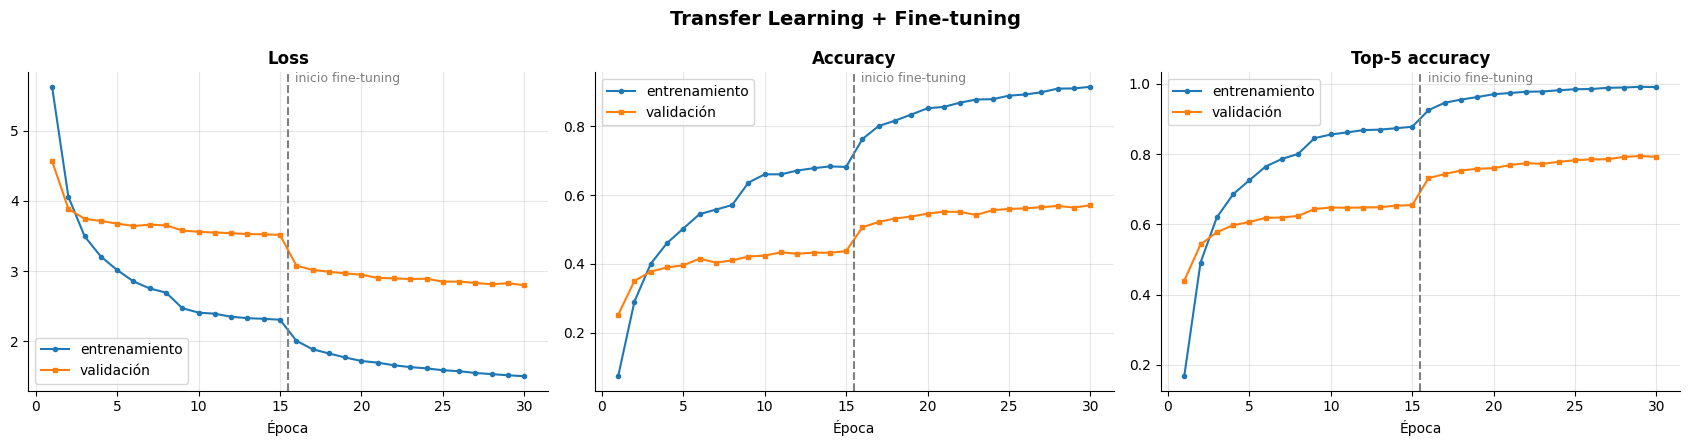

In [25]:
base.trainable = True
for capa in base.layers[:-FT_LAYERS]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False

print(f"Capas entrenables en la base: {sum(c.trainable for c in base.layers)} de {len(base.layers)}")
compilar(modelo_tl, 1e-4)

ep_fase1 = len(hist_tl.history["loss"])
hist_ft = modelo_tl.fit(train_ds, validation_data=val_ds, epochs=ep_fase1 + EPOCHS_FT,
                        initial_epoch=ep_fase1, callbacks=callbacks("tl_finetuning", paciencia=5))
graficar_historia([hist_tl, hist_ft], "Transfer Learning + Fine-tuning", corte=ep_fase1)

## <FONT SIZE=4 COLOR="green"> 9. Evaluación en el conjunto de test </FONT>

In [26]:
y_true = df_test["y"].values

def evaluar(modelo, nombre):
    probs = modelo.predict(test_ds, verbose=0)
    pred = probs.argmax(1)
    top5 = np.mean([y in np.argsort(p)[-5:] for y, p in zip(y_true, probs)])
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    return probs, {"Modelo": nombre, "Accuracy": accuracy_score(y_true, pred), "Top-5 accuracy": top5,
                   "Precision (macro)": p, "Recall (macro)": r, "F1-score (macro)": f1}

probs_base, m_base = evaluar(modelo_base, "CNN desde cero")
probs_tl, m_tl = evaluar(modelo_tl, "EfficientNetV2B0 + fine-tuning")

tabla_metricas = pd.DataFrame([m_base, m_tl]).set_index("Modelo")
tabla_metricas.style.format("{:.2%}").background_gradient(cmap="Greens", axis=0)

,Accuracy,Top-5 accuracy,Precision (macro),Recall (macro),F1-score (macro)
Modelo,,,,,
CNN desde cero,9.59%,28.53%,9.94%,9.51%,8.00%
EfficientNetV2B0 + fine-tuning,59.57%,80.32%,61.76%,59.51%,59.16%


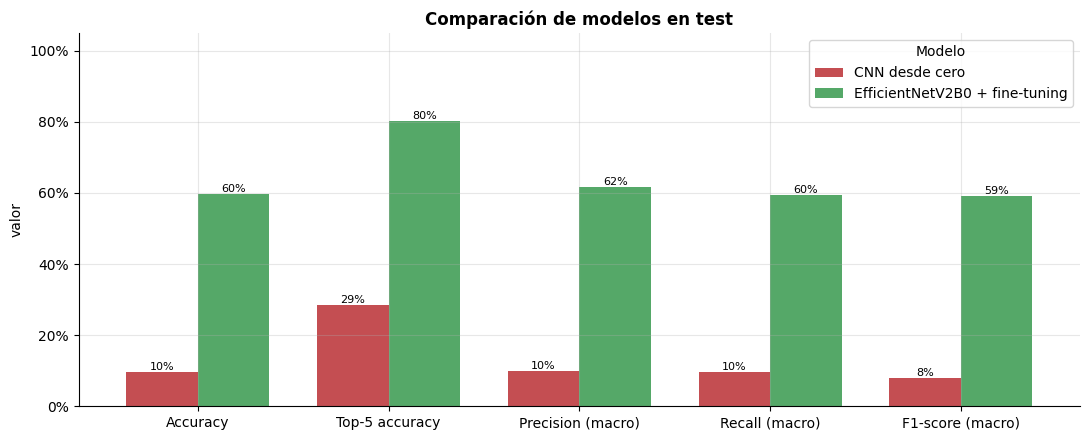

In [27]:
ax = tabla_metricas.T.plot.bar(figsize=(11, 4.5), color=["#C44E52", "#55A868"], width=0.75)
ax.set_title("Comparación de modelos en test"); ax.set_ylim(0, 1.05); ax.set_ylabel("valor")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.tick_params(axis="x", rotation=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt=lambda v: f"{v:.0%}", fontsize=8)
plt.tight_layout(); plt.show()

A partir de aquí se analiza el **mejor modelo** (Transfer Learning + Fine-tuning).

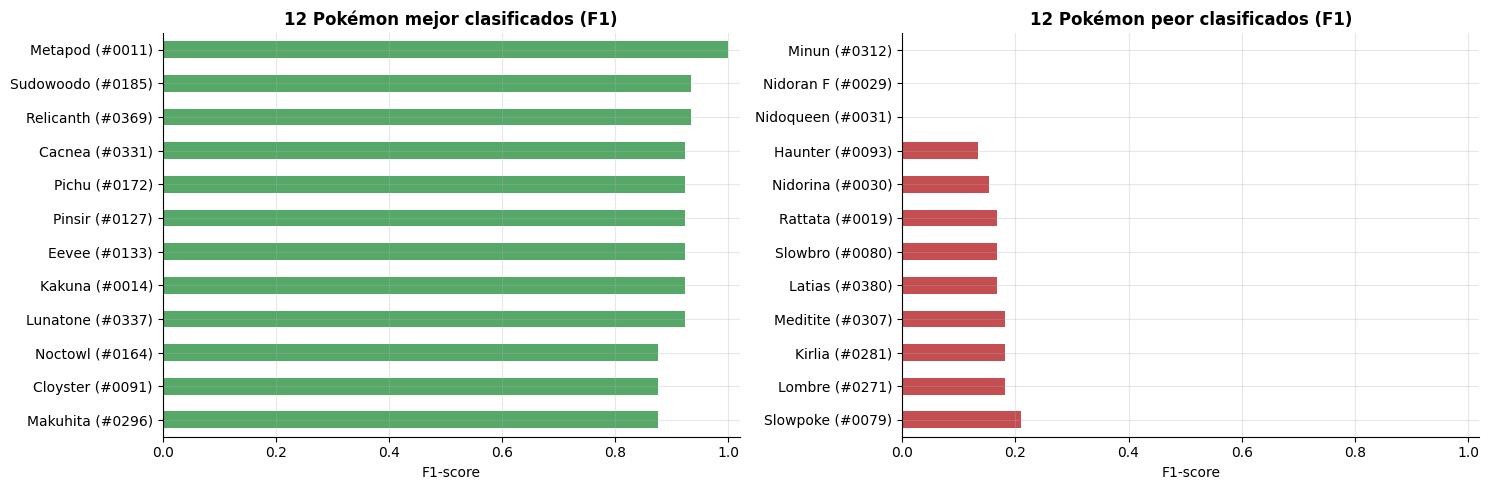

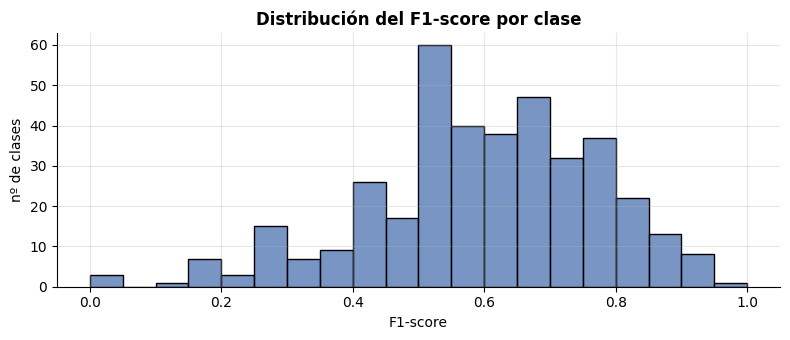

In [28]:
y_pred = probs_tl.argmax(1)
NOMBRES = [nombre_bonito(c) for c in CLASES]
rep = pd.DataFrame(classification_report(y_true, y_pred, labels=range(NUM_CLASES), target_names=NOMBRES,
                                         output_dict=True, zero_division=0)).T.iloc[:NUM_CLASES]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
rep["f1-score"].sort_values().tail(12).plot.barh(ax=axes[0], color="#55A868")
axes[0].set_title("12 Pokémon mejor clasificados (F1)")
rep["f1-score"].sort_values().head(12).iloc[::-1].plot.barh(ax=axes[1], color="#C44E52")
axes[1].set_title("12 Pokémon peor clasificados (F1)")
for ax in axes: ax.set_xlim(0, 1.02); ax.set_xlabel("F1-score")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 3.5))
sns.histplot(rep["f1-score"], bins=20, color="#4C72B0")
plt.title("Distribución del F1-score por clase"); plt.xlabel("F1-score"); plt.ylabel("nº de clases")
plt.tight_layout(); plt.show()

### Matriz de confusión
Con 386 clases la matriz completa no es legible, así que se muestran (1) los pares de Pokémon que más se confunden
y (2) la matriz de confusión restringida a las clases involucradas en esas confusiones.

,Real,Predicho como,Nº de errores
0,Minun (#0312),Plusle (#0311),5
1,Porygon2 (#0233),Porygon (#0137),5
2,Poliwrath (#0062),Poliwhirl (#0061),4
3,Ninjask (#0291),Nincada (#0290),4
4,Houndour (#0228),Houndoom (#0229),4
5,Lombre (#0271),Lotad (#0270),4
6,Lairon (#0305),Aron (#0304),3
7,Volbeat (#0313),Illumise (#0314),3
8,Wailord (#0321),Wailmer (#0320),3
9,Weepinbell (#0070),Victreebel (#0071),3


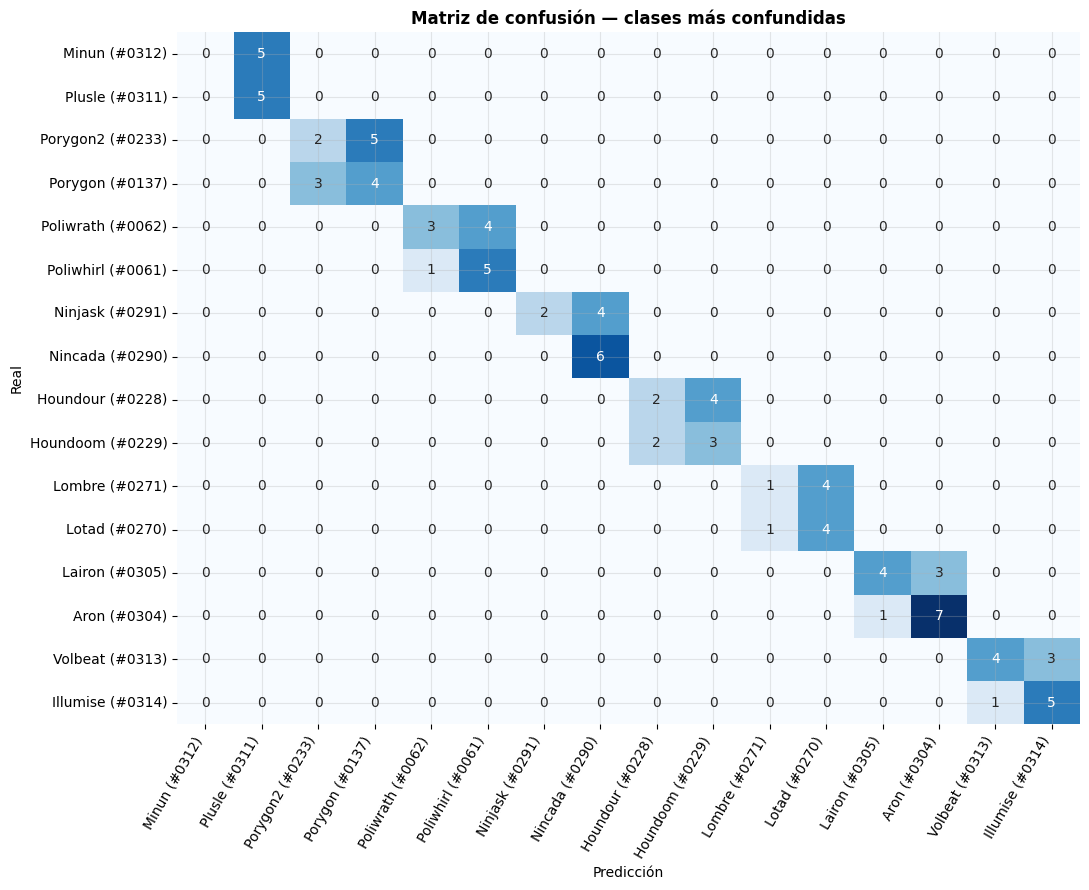

In [29]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASES))
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pares = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1], cm.shape))[0]
pares = [(i, j) for i, j in pares if cm_off[i, j] > 0][:15]
tabla_conf = pd.DataFrame([(NOMBRES[i], NOMBRES[j], cm_off[i, j]) for i, j in pares],
                          columns=["Real", "Predicho como", "Nº de errores"])
display(tabla_conf)

idx = list(dict.fromkeys([k for par in pares for k in par]))[:16]
sub = cm[np.ix_(idx, idx)]
plt.figure(figsize=(11, 9))
sns.heatmap(sub, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=[NOMBRES[k] for k in idx], yticklabels=[NOMBRES[k] for k in idx])
plt.title("Matriz de confusión — clases más confundidas"); plt.xlabel("Predicción"); plt.ylabel("Real")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

## <FONT SIZE=4 COLOR="green"> 10. Predicciones </FONT>

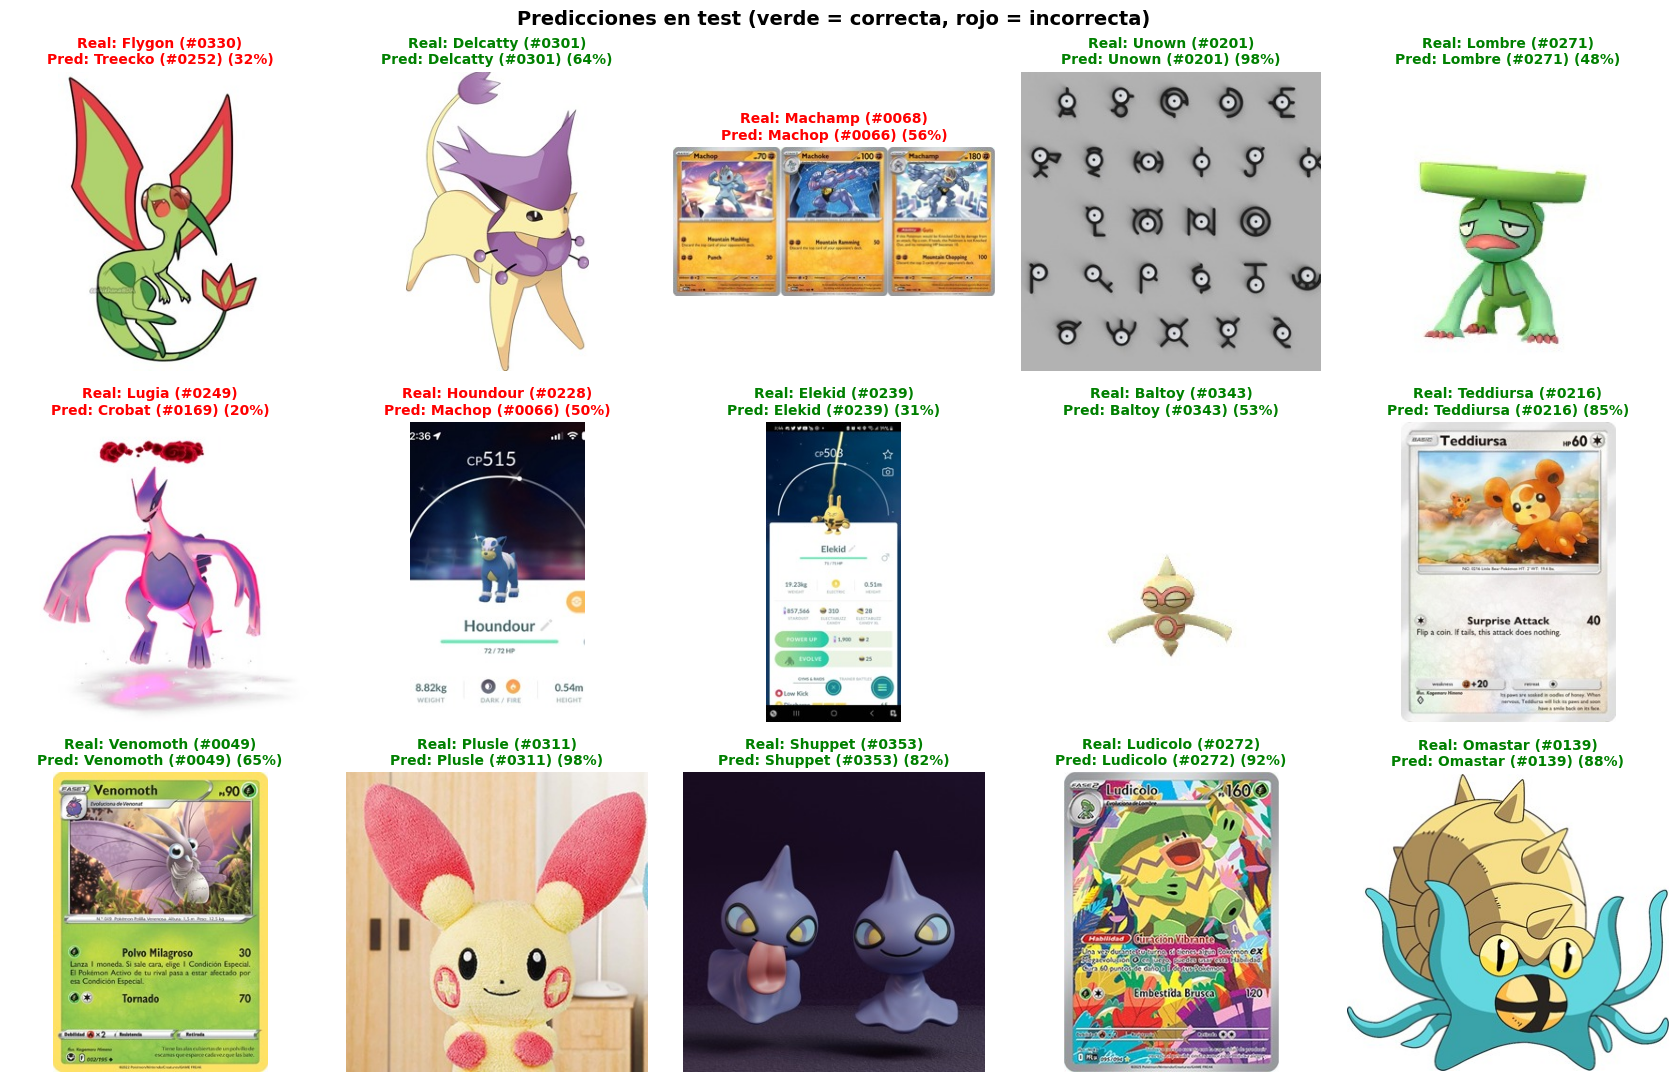

In [30]:
# 15 imágenes de test al azar: verde = acierto, rojo = error
sel = np.random.default_rng(SEED).choice(len(df_test), 15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(17, 11))
for ax, k in zip(axes.ravel(), sel):
    ax.imshow(Image.open(df_test["ruta"].iloc[k])); ax.axis("off")
    p = probs_tl[k]; pred = p.argmax(); real = y_true[k]
    color = "green" if pred == real else "red"
    ax.set_title(f"Real: {NOMBRES[real]}\nPred: {NOMBRES[pred]} ({p[pred]:.0%})", color=color, fontsize=10)
plt.suptitle("Predicciones en test (verde = correcta, rojo = incorrecta)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

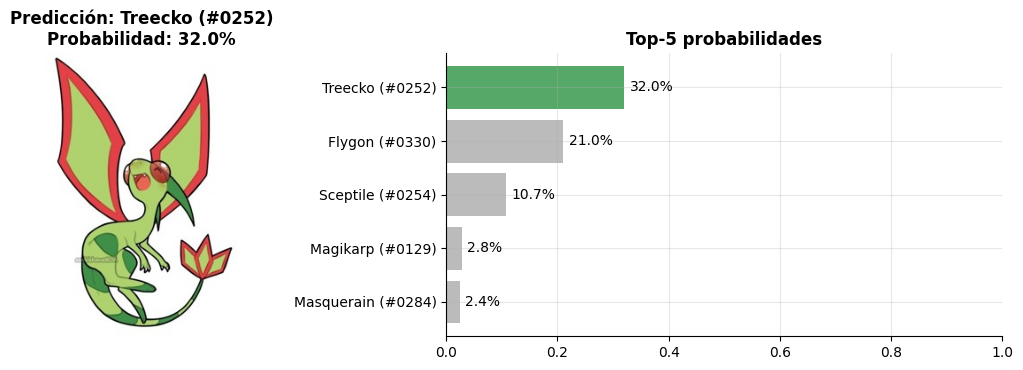

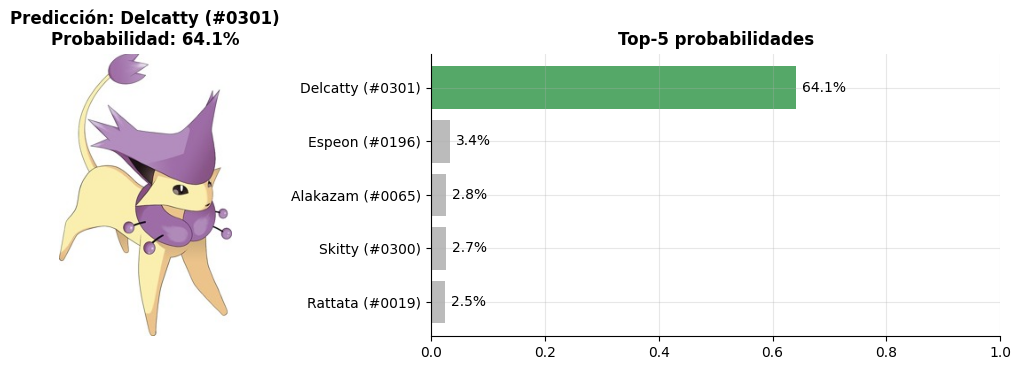

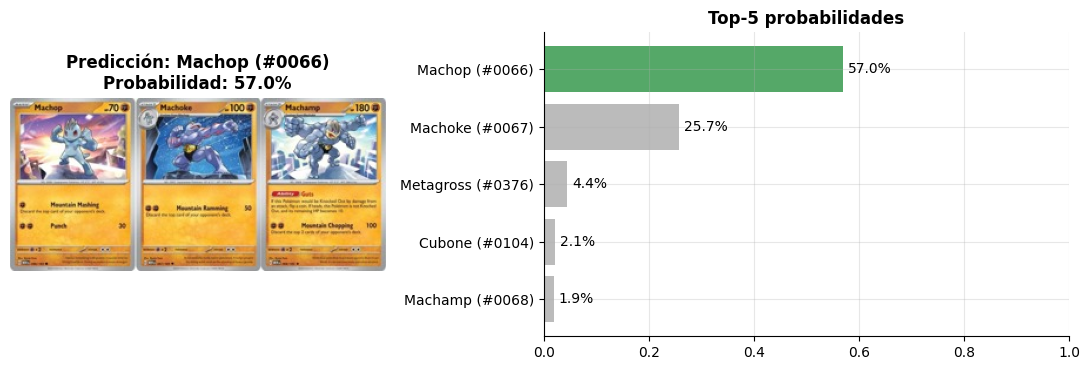

In [31]:
def predecir_imagen(imagen, modelo=modelo_tl, top_k=5):
    # 'imagen' puede ser una ruta, un PIL.Image o un arreglo numpy. Devuelve [(nombre, probabilidad), ...]
    if isinstance(imagen, (str, Path)):
        imagen = Image.open(imagen)
    if isinstance(imagen, np.ndarray):
        imagen = Image.fromarray(imagen.astype("uint8"))
    imagen = ImageOps.exif_transpose(imagen)
    if imagen.mode in ("RGBA", "LA", "P"):
        imagen = imagen.convert("RGBA")
        imagen = Image.alpha_composite(Image.new("RGBA", imagen.size, (255, 255, 255, 255)), imagen)
    x = np.asarray(imagen.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32)[None]
    p = modelo.predict(x, verbose=0)[0]
    top = np.argsort(p)[::-1][:top_k]
    return [(NOMBRES[i], float(p[i])) for i in top]

def mostrar_prediccion(ruta):
    res = predecir_imagen(ruta)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
    axes[0].imshow(Image.open(ruta).convert("RGB")); axes[0].axis("off")
    axes[0].set_title(f"Predicción: {res[0][0]}\nProbabilidad: {res[0][1]:.1%}")
    nombres, ps = zip(*res[::-1])
    axes[1].barh(nombres, ps, color=["#BBBBBB"] * (len(ps) - 1) + ["#55A868"])
    axes[1].set_xlim(0, 1); axes[1].set_title("Top-5 probabilidades")
    for i, v in enumerate(ps): axes[1].text(v + 0.01, i, f"{v:.1%}", va="center")
    plt.tight_layout(); plt.show()

for k in sel[:3]:
    mostrar_prediccion(df_test["ruta"].iloc[k])

# Para probar con una imagen propia:
# mostrar_prediccion("mi_imagen.jpg")

## <FONT SIZE=4 COLOR="green"> 11. Guardar el modelo para la aplicación Gradio </FONT>
Se guardan el modelo entrenado (`.keras`) y la lista de clases (`.json`). La interfaz solo carga estos archivos,
no vuelve a entrenar.

In [32]:
modelo_tl.save(MODEL_PATH)
with open(CLASSES_PATH, "w", encoding="utf-8") as f:
    json.dump({"img_size": IMG_SIZE, "clases": NOMBRES}, f, ensure_ascii=False, indent=1)
tabla_metricas.to_csv(WORK_DIR / "metricas_cnn.csv")
print("Guardado:", MODEL_PATH, "|", CLASSES_PATH)

if EN_COLAB:   # descargar al computador
    from google.colab import files
    files.download(str(MODEL_PATH)); files.download(str(CLASSES_PATH))

Guardado: /content/modelo_cnn_pokemon.keras | /content/clases_pokemon.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Módulo 2 de Gradio (vista previa)
Esta celda es la misma lógica que se usa en el archivo `.py` de la aplicación: carga el modelo guardado,
recibe una imagen y muestra la clase predicha con su probabilidad (top-5).

In [33]:
try:
    import gradio as gr
except ImportError:
    !pip -q install gradio
    import gradio as gr

modelo_app = keras.models.load_model(MODEL_PATH)
with open(CLASSES_PATH, encoding="utf-8") as f:
    meta = json.load(f)

def clasificar(img):
    if img is None:
        return {}, ""
    res = predecir_imagen(img, modelo=modelo_app, top_k=5)
    nombre, prob = res[0]
    return dict(res), f"### Es **{nombre}** con una probabilidad de **{prob:.1%}**"

with gr.Blocks(title="Clasificador de Pokémon (CNN)") as demo_cnn:
    gr.Markdown("## Módulo 2 · Redes Convolucionales — ¿Qué Pokémon es?")
    with gr.Row():
        entrada_img = gr.Image(type="pil", label="Sube una imagen")
        with gr.Column():
            salida_txt = gr.Markdown()
            salida_lbl = gr.Label(num_top_classes=5, label="Probabilidades (top-5)")
    gr.Button("Predecir", variant="primary").click(clasificar, entrada_img, [salida_lbl, salida_txt])
    gr.Examples(examples=df_test["ruta"].sample(6, random_state=1).tolist(), inputs=entrada_img)

demo_cnn.launch(share=EN_COLAB)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d374bae2557aee4ec7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## <FONT SIZE=4 COLOR="green"> 12. Conclusiones </FONT>

_(Ajustar los valores con los resultados obtenidos en la tabla de la sección 9.)_

- **El Transfer Learning es decisivo con pocos datos por clase.** La CNN entrenada desde cero, con solo ≈35 imágenes de
  entrenamiento por clase, aprende patrones generales (colores, formas) pero no logra separar bien 386 clases y su
  accuracy en test queda baja. EfficientNetV2-B0, que trae características visuales aprendidas en ImageNet, alcanza
  una accuracy muy superior con el mismo dataset y en menos épocas.
- **El fine-tuning aporta una mejora adicional**: al ajustar las últimas capas, la red adapta sus filtros al estilo
  de los Pokémon (dibujos planos, contornos marcados, colores saturados), diferente a las fotos de ImageNet.
- **La top-5 accuracy es mucho mayor que la top-1**: cuando el modelo falla, casi siempre la clase correcta está entre
  sus primeras opciones.
- **Los errores tienen sentido:** las confusiones más frecuentes ocurren entre Pokémon de la misma línea evolutiva o de
  apariencia muy similar (p. ej. Nidoran ♀/♂, Mankey/Primeape, Voltorb/Electrode), y en clases con imágenes ruidosas.
- **Data Augmentation y label smoothing** reducen el sobreajuste: la brecha entre las curvas de entrenamiento y validación
  es moderada.
- **Mejoras posibles:** depurar manualmente las imágenes mal etiquetadas del scraping, conseguir más imágenes por clase,
  usar una red más grande (EfficientNetV2-S, ConvNeXt) o mayor resolución.